In [1]:
%pip install pandas numpy scipy scikit-learn matplotlib seaborn mlxtend

  Using cached mlxtend-0.25.0-py3-none-any.whl.metadata (7.4 kB)
Using cached mlxtend-0.25.0-py3-none-any.whl (1.4 MB)
Note: you may need to restart the kernel to use updated packages.


Données : ../data/données.csv (73930, 28)

0. LIBELLES PRODUITS
Table des codes : 28 lignes (inclut SEXE et id)
  Colonnes du dataset sans libellé : aucune
  Codes de la table absents du dataset : ['SEXE', 'id']

1. NETTOYAGE
Dimensions brutes : (73930, 28)
Lignes entièrement dupliquées (supprimées) : 1265
Lignes dont l'id est partagé avec un autre client (conservées) : 54
  -> détail dans anomalies_id_dupliques.csv ; l'id n'est donc pas une clé fiable
SEXE manquant remplacé par 'Inconnu' : 1283 clients
Produits détenus à plus de 95 % : ['DAV']
Dimensions après nettoyage : (72665, 29)

2. EXPLORATION : DETENTION, CO-DETENTION, SEXE


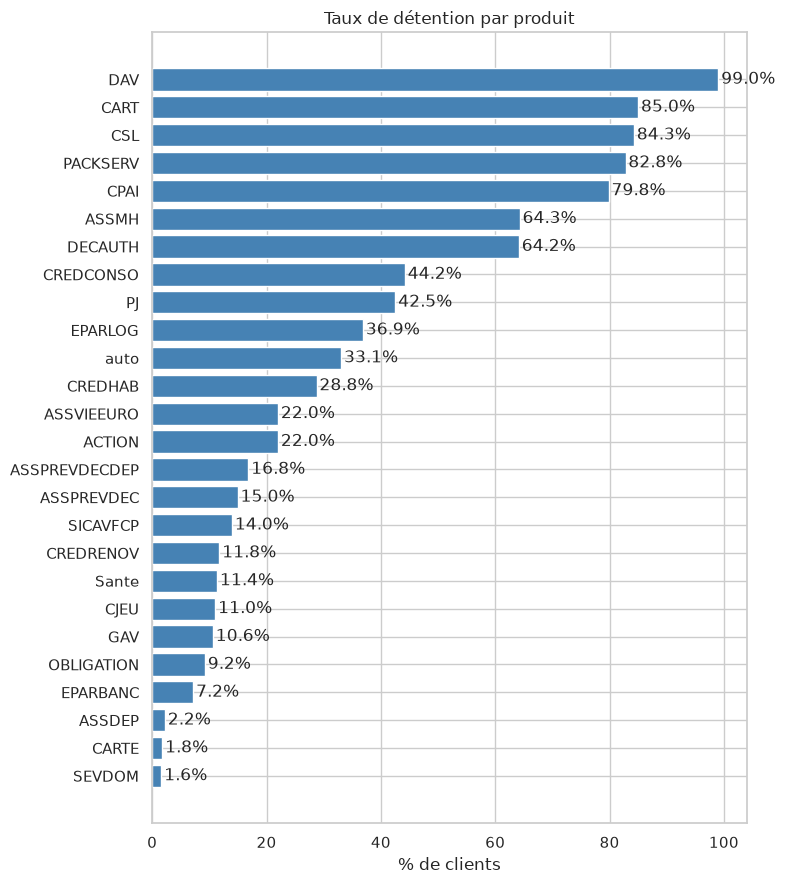

Produits par client : moyenne 9.02, médiane 9


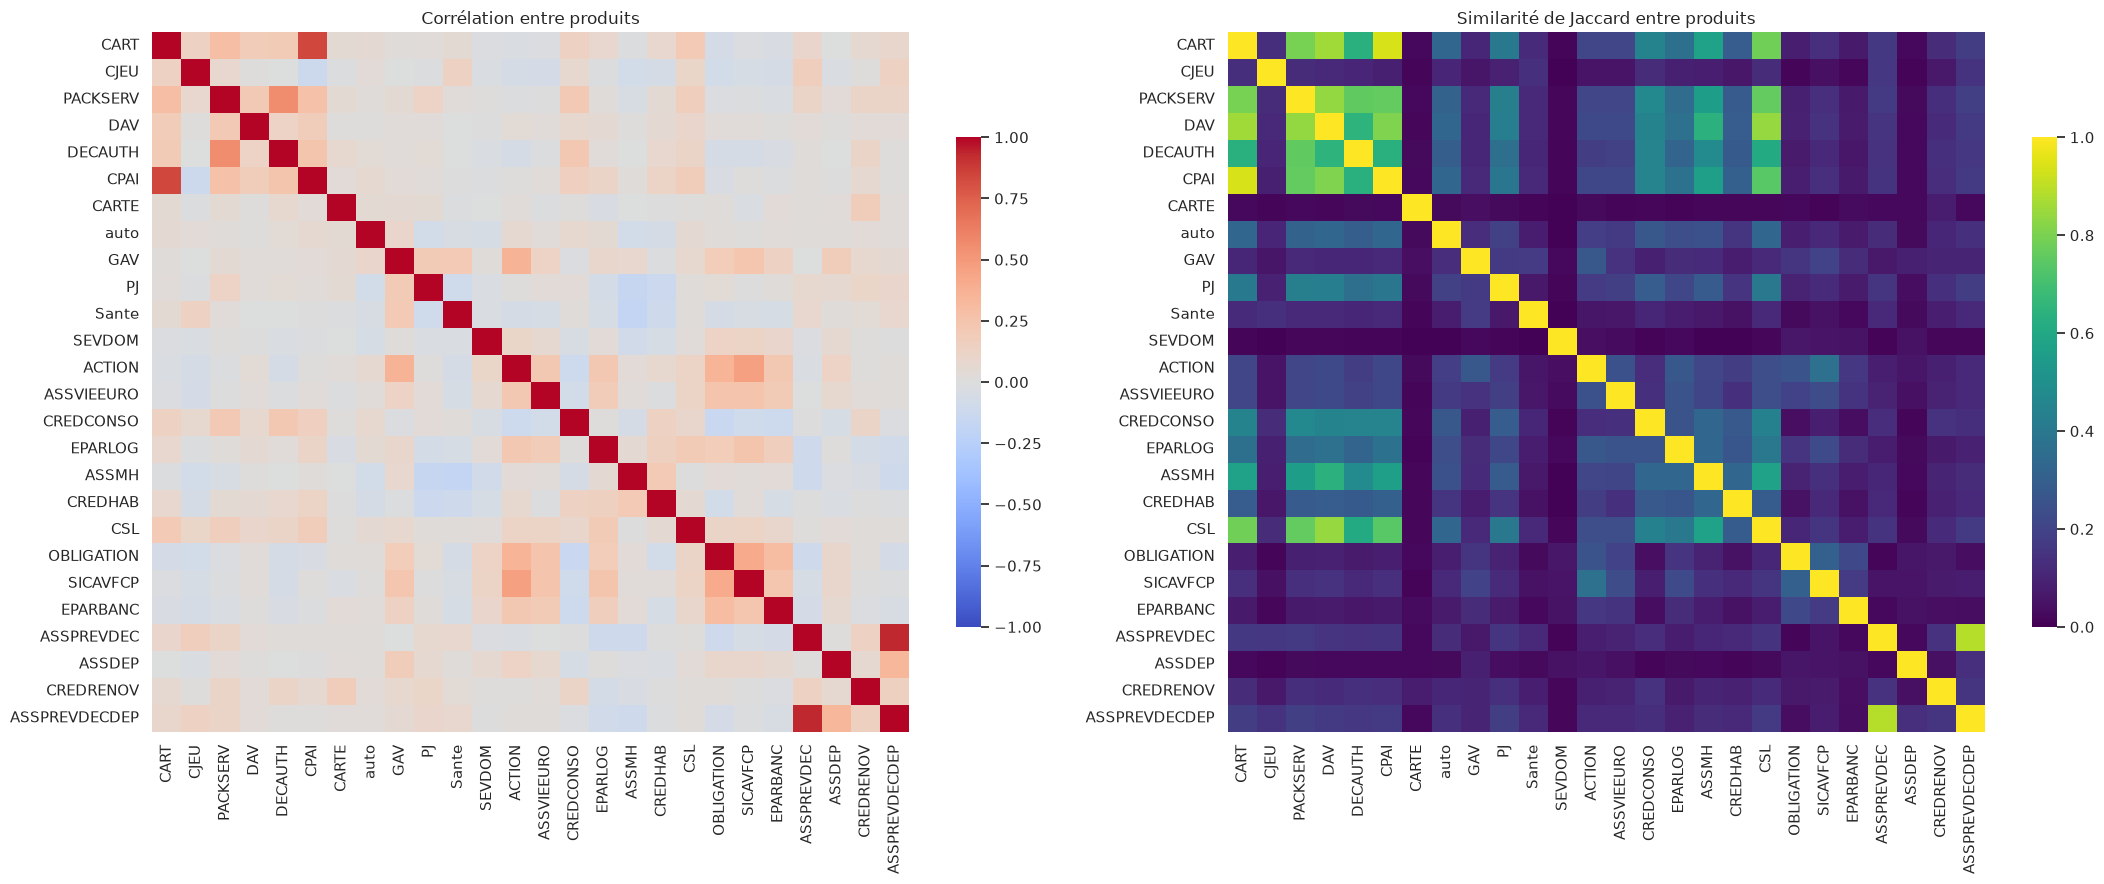


Top 10 des paires les plus corrélées :
ASSPREVDEC  ASSPREVDECDEP    0.933
CART        CPAI             0.836
PACKSERV    DECAUTH          0.562
ACTION      SICAVFCP         0.461
OBLIGATION  SICAVFCP         0.411
GAV         ACTION           0.365
ACTION      OBLIGATION       0.359
ASSDEP      ASSPREVDECDEP    0.337
OBLIGATION  EPARBANC         0.302
CART        PACKSERV         0.296

Redondances logiques :
  ASSPREVDECDEP = ASSPREVDEC OU ASSDEP : vrai pour 100.0% des clients
  Clients avec CPAI sans CART : 0  (CPAI est quasi inclus dans CART)

Écarts F/M les plus marqués (hors 'Inconnu') :
  produit  taux_F_%  taux_M_%  ecart_M_moins_F_pts
  CREDHAB      18.0      36.4                 18.4
CREDCONSO      38.7      48.2                  9.5
     auto      28.6      35.9                  7.3
  EPARLOG      33.1      39.4                  6.3
   ACTION      18.8      24.2                  5.4
    Sante      13.2      10.1                 -3.1
      GAV       8.8      11.7             

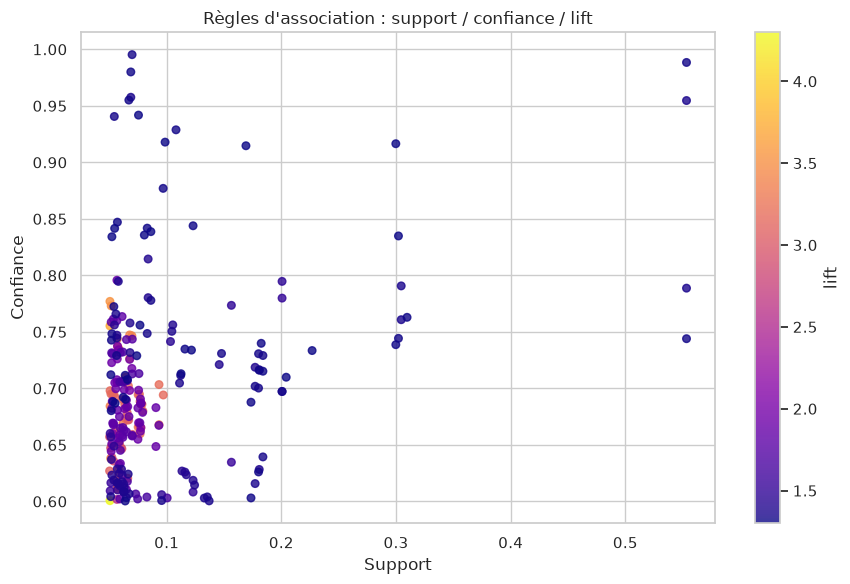


4. SEGMENTATION (SVD + K-Means)
  k=3  silhouette=0.148  inertie=139,406
  k=4  silhouette=0.136  inertie=127,809
  k=5  silhouette=0.134  inertie=119,114
  k=6  silhouette=0.136  inertie=112,666
  k=7  silhouette=0.126  inertie=107,425
  k=8  silhouette=0.136  inertie=103,181
-> k retenu : 3  (silhouette faible = clusters peu séparés, à nuancer dans le rapport)


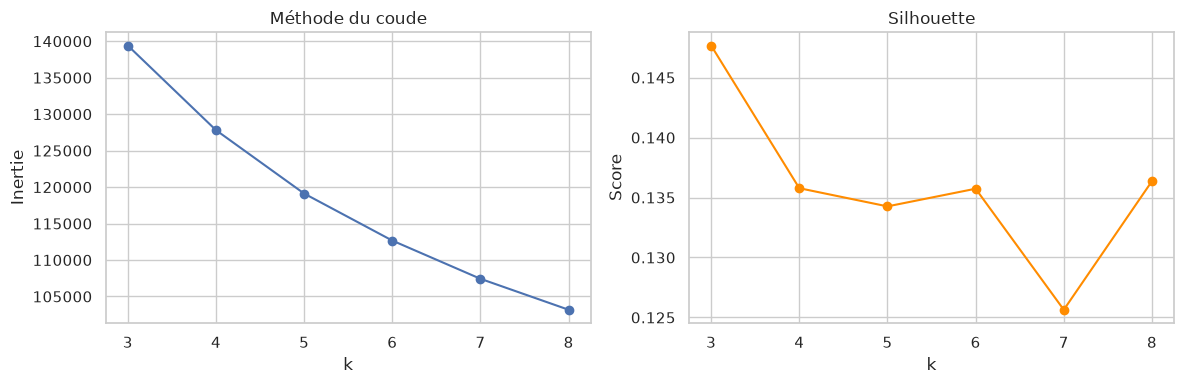


Profil des clusters (écart à la moyenne, en points de %) :
  Cluster 0 - 54.5% des clients, 8.31 produits en moyenne
      surreprésenté : DECAUTH (+26.5), CREDCONSO (+20.8), PACKSERV (+16.7), CPAI (+13.4)
      sous-représenté : SICAVFCP (-10.6), ACTION (-14.5)
  Cluster 1 - 19.1% des clients, 10.47 produits en moyenne
      surreprésenté : ACTION (+58.1), SICAVFCP (+43.3), EPARLOG (+39.7), ASSVIEEURO (+36.4)
      sous-représenté : ASSPREVDEC (-6.3), CREDCONSO (-19.5)
  Cluster 2 - 26.4% des clients, 5.02 produits en moyenne
      surreprésenté : CJEU (+1.6), Sante (+0.5), ASSMH (+0.4), SEVDOM (-0.4)
      sous-représenté : PACKSERV (-36.6), DECAUTH (-52.1)


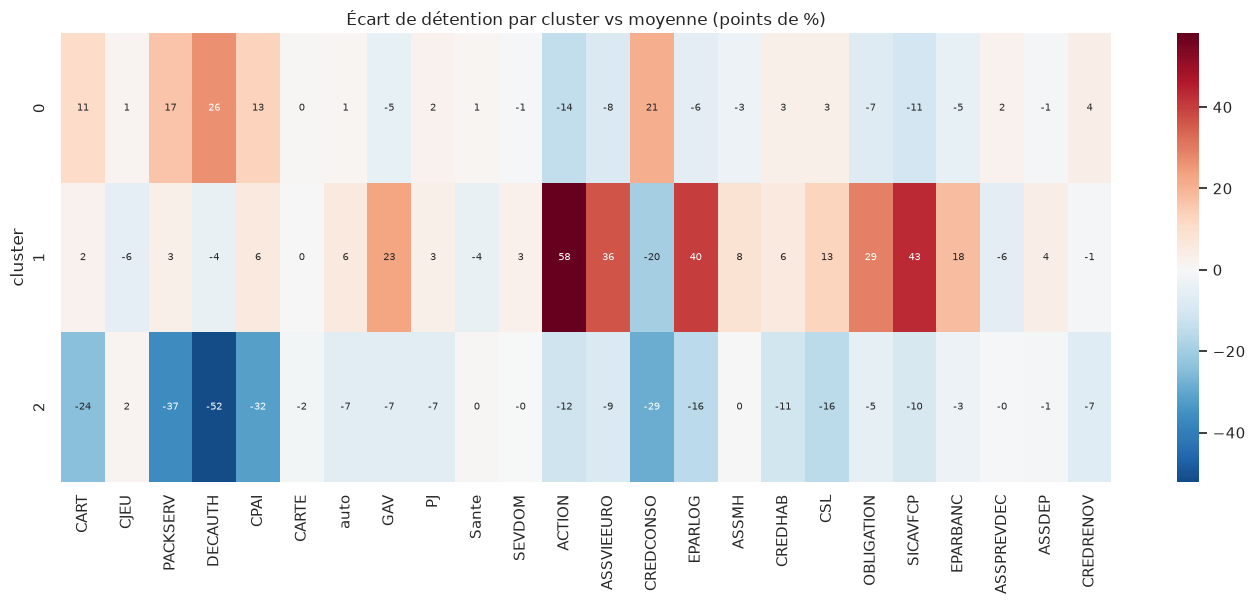

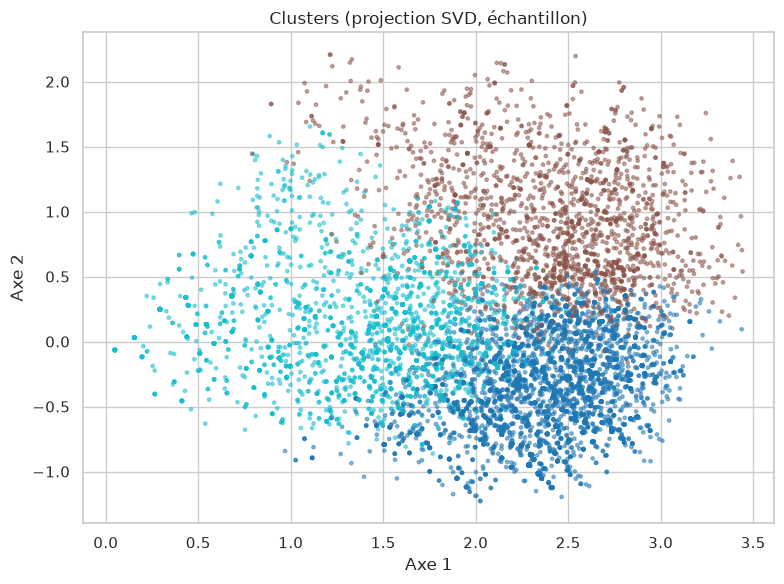


TERMINE
Résultats dans : /home/etudiant/master 2 siad DS/data mining/projet-data-mining/outputs


In [2]:
   import sys
   sys.path.append("..")

   import importlib
   import projet_datamining as pdm
   importlib.reload(pdm)

   df = pdm.main()